# 04 – XGBoost Regressor

**Ziel:** XGBoost als stärkstes tabellares ML-Modell auf NASA CMAPSS FD003.  
XGBoost ist in publizierten CMAPSS-Benchmarks typischerweise das beste  
nicht-sequentielle Modell (vor LSTM/Transformer).

**Unterschied zu Random Forest:**  
RF baut Bäume parallel und mittelt. XGBoost baut Bäume *sequenziell* —  
jeder Baum korrigiert die Fehler des vorherigen (Gradient Boosting).  
Das erlaubt tieferes Fitting auf Patterns, braucht aber mehr Tuning.

> **Reproduzierbarkeit:** Originallauf (Juni 2026, Windows): RMSE 20.84, NASA 1941. Neulauf auf macOS (Oktober 2026, gleiche Paketversionen): RMSE 20.45, NASA 1801.  
> Die Abweichung entsteht durch Fließkomma-Unterschiede zwischen Plattformen. Schon die unveränderte Baseline weicht ab (beste Iteration 112 statt 85), danach wählen die Grid Searches andere Parameter. README und Vergleich nennen die Werte des Originallaufs
> (`ml/reports/model_results_original.json`); die Ausgaben unten zeigen den Neulauf.

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, GroupKFold

from src.data.loader import load_train, load_test, get_feature_cols
from src.evaluation.metrics import evaluate_all
from src.config import XGB_PARAMS, REPORTS

sns.set_theme(style='whitegrid')
print('Setup fertig.')

Setup fertig.


## 1. Daten laden

In [2]:
train = load_train()
test  = load_test()

feature_cols = get_feature_cols('raw+rolling')

X_train = train[feature_cols]
y_train = train['RUL']
groups  = train['unit_number']

X_test  = test[feature_cols]
y_test  = test['RUL_true']

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train geladen: 24320 Zeilen (400 Rolling-NAs entfernt)
Test geladen: 100 Zeilen (eine pro Engine)
Train: (24320, 36)  |  Test: (100, 36)


## 2. Train/Validation Split für Early Stopping

XGBoost's Early Stopping braucht ein separates Validation-Set während des Trainings.  
Wir nehmen einen GroupKFold-Split: 80 Engines Train, 20 Engines Validation.  
So sieht XGBoost keine Engine doppelt.

In [3]:
gkf = GroupKFold(n_splits=5)

# Ersten Fold nehmen für Early Stopping
train_idx, val_idx = next(gkf.split(X_train, y_train, groups=groups))

X_tr = X_train.iloc[train_idx]
y_tr = y_train.iloc[train_idx]
X_val = X_train.iloc[val_idx]
y_val = y_train.iloc[val_idx]

print(f'Train-Fold: {X_tr.shape}  |  Val-Fold: {X_val.shape}')

Train-Fold: (19458, 36)  |  Val-Fold: (4862, 36)


## 3. Baseline XGBoost mit Early Stopping

In [4]:
xgb_baseline = xgb.XGBRegressor(**XGB_PARAMS)

xgb_baseline.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f'Beste Iteration: {xgb_baseline.best_iteration}')
print(f'Bestes Val-RMSE: {xgb_baseline.best_score:.3f}')

y_pred_baseline = xgb_baseline.predict(X_test)
results_baseline = evaluate_all(y_test.values, y_pred_baseline, 'XGB Baseline')
print(results_baseline)

Beste Iteration: 112
Bestes Val-RMSE: 18.823
{'Model': 'XGB Baseline', 'RMSE': 21.1, 'MAE': 15.82, 'R²': 0.74, 'NASA Score': 2046.8}


## 4. Learning Curve

Zeigt wann Overfitting beginnt → motiviert Early Stopping visuell.

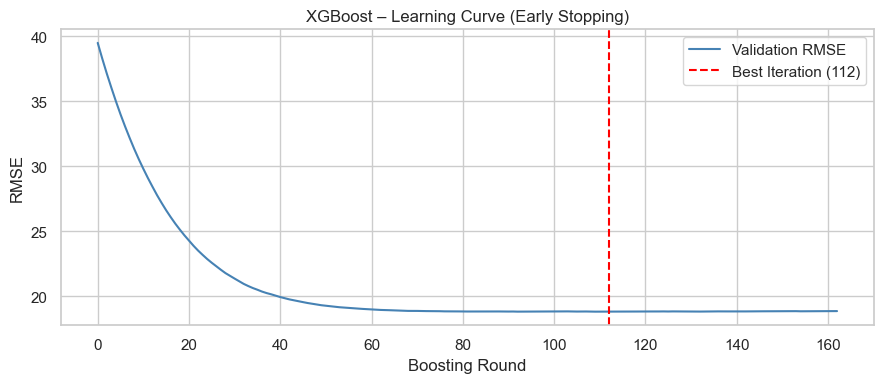

In [5]:
results = xgb_baseline.evals_result()
val_rmse = results['validation_0']['rmse']
epochs = len(val_rmse)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(epochs), val_rmse, label='Validation RMSE', color='steelblue')
ax.axvline(xgb_baseline.best_iteration, color='red', linestyle='--',
           label=f'Best Iteration ({xgb_baseline.best_iteration})')
ax.set_xlabel('Boosting Round')
ax.set_ylabel('RMSE')
ax.set_title('XGBoost – Learning Curve (Early Stopping)')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / 'xgb_learning_curve.png', dpi=150)
plt.show()

## 5. Hyperparameter-Tuning (stufenweise)

Statt Grid über alles auf einmal: erst max_depth + min_child_weight tunen,  
dann subsample + colsample_bytree. Weniger Rechenaufwand, gleich gute Ergebnisse.

In [6]:
# Stufe 1: Tree-Struktur
param_grid_1 = {
    'max_depth':        [4, 6, 8],
    'min_child_weight': [1, 5, 10],
}

base_params = {
    'n_estimators':   300,   # fix für Grid Search (kein Early Stopping in GridSearchCV)
    'learning_rate':  0.05,
    'subsample':      0.8,
    'colsample_bytree': 0.8,
    'random_state':   42,
    'n_jobs':         1,   # parallelisiert wird über GridSearchCV (keine Überbelegung)
}

grid_xgb_1 = GridSearchCV(
    xgb.XGBRegressor(**base_params),
    param_grid_1,
    cv=GroupKFold(n_splits=5),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)
grid_xgb_1.fit(X_train, y_train, groups=groups)

best_depth = grid_xgb_1.best_params_['max_depth']
best_mcw   = grid_xgb_1.best_params_['min_child_weight']
print(f'Stufe 1 – Beste Parameter: {grid_xgb_1.best_params_}')
print(f'Stufe 1 – Bestes CV-RMSE:  {-grid_xgb_1.best_score_:.2f}')

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Stufe 1 – Beste Parameter: {'max_depth': 4, 'min_child_weight': 5}
Stufe 1 – Bestes CV-RMSE:  17.15


In [7]:
# Stufe 2: Sampling
param_grid_2 = {
    'subsample':       [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
}

base_params_2 = base_params | {'max_depth': best_depth, 'min_child_weight': best_mcw}

grid_xgb_2 = GridSearchCV(
    xgb.XGBRegressor(**base_params_2),
    param_grid_2,
    cv=GroupKFold(n_splits=5),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)
grid_xgb_2.fit(X_train, y_train, groups=groups)

print(f'Stufe 2 – Beste Parameter: {grid_xgb_2.best_params_}')
print(f'Stufe 2 – Bestes CV-RMSE:  {-grid_xgb_2.best_score_:.2f}')

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Stufe 2 – Beste Parameter: {'colsample_bytree': 0.6, 'subsample': 0.6}
Stufe 2 – Bestes CV-RMSE:  17.08


## 6. Finales Modell – bestes Tuning + Early Stopping

In [8]:
best_params = grid_xgb_2.best_params_ | grid_xgb_1.best_params_

# Schritt 1: Optimale Anzahl Bäume via Early Stopping finden
xgb_es = xgb.XGBRegressor(
    **best_params,
    n_estimators=1000,
    learning_rate=0.05,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb_es.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=False
)
best_n = xgb_es.best_iteration
print(f"Optimale Anzahl Bäume: {best_n}")

# Schritt 2: Mit dieser Anzahl auf ALLEN Trainingsdaten neu trainieren
xgb_final = xgb.XGBRegressor(
    **best_params,
    n_estimators=best_n,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
)
xgb_final.fit(X_train, y_train)  # volles X_train, nicht X_tr

y_pred_xgb = xgb_final.predict(X_test)
results_xgb = evaluate_all(y_test.values, y_pred_xgb, 'XGBoost')
print(pd.DataFrame([results_xgb]).set_index('Model').to_string())

Optimale Anzahl Bäume: 82
          RMSE    MAE     R²  NASA Score
Model                                   
XGBoost  20.45  15.21  0.756      1801.4


## 7. Feature Importance (Vergleich mit Random Forest)


Top-10 Features:
            Feature  Importance
 sensor_3_roll_mean    0.261051
sensor_11_roll_mean    0.249915
sensor_17_roll_mean    0.204994
          sensor_11    0.068266
 sensor_4_roll_mean    0.030351
sensor_14_roll_mean    0.028721
          sensor_14    0.027722
sensor_15_roll_mean    0.017452
 sensor_2_roll_mean    0.010325
           sensor_4    0.009203


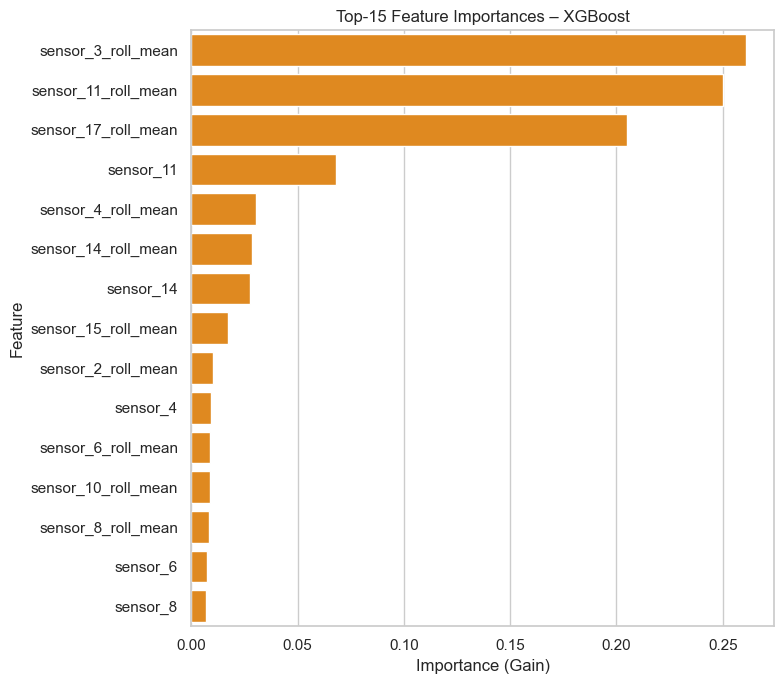

In [9]:
importance_df = pd.DataFrame({
    'Feature':    feature_cols,
    'Importance': xgb_final.feature_importances_
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(
    data=importance_df.head(15),
    x='Importance', y='Feature',
    color='darkorange', ax=ax
)
ax.set_title('Top-15 Feature Importances – XGBoost')
ax.set_xlabel('Importance (Gain)')
plt.tight_layout()
plt.savefig(REPORTS / 'xgb_feature_importance.png', dpi=150)
plt.show()

print('\nTop-10 Features:')
print(importance_df.head(10).to_string(index=False))

## 8. Predicted vs. Actual

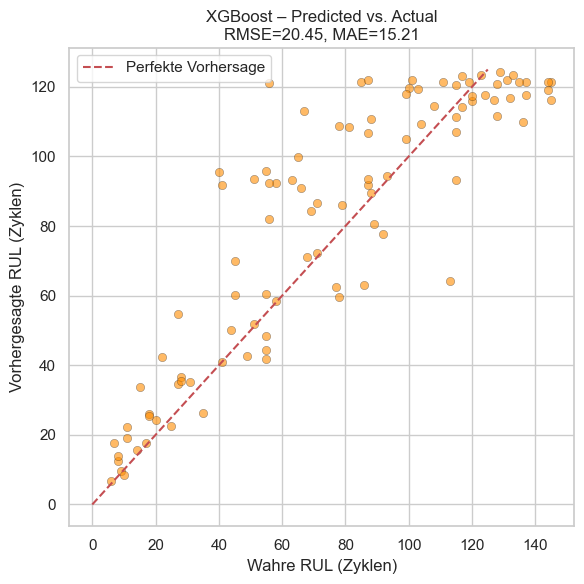

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_xgb, alpha=0.6, color='darkorange', edgecolors='k', linewidths=0.3)
ax.plot([0, 125], [0, 125], 'r--', label='Perfekte Vorhersage')
ax.set_xlabel('Wahre RUL (Zyklen)')
ax.set_ylabel('Vorhergesagte RUL (Zyklen)')
ax.set_title(f'XGBoost – Predicted vs. Actual\nRMSE={results_xgb["RMSE"]}, MAE={results_xgb["MAE"]}')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / 'xgb_predicted_vs_actual.png', dpi=150)
plt.show()

## 9. Ergebnisse speichern

In [11]:
from src.evaluation.results import save_results, save_predictions

# Metriken → model_results.json, Vorhersagen pro Engine → predictions_test.csv
save_results(results_xgb)
save_predictions('XGBoost', test['unit_number'], y_test, y_pred_xgb)

Metriken gespeichert: model_results.json → {'Model': 'XGBoost', 'RMSE': 20.45, 'MAE': 15.21, 'R²': 0.756, 'NASA Score': 1801.4}
Vorhersagen gespeichert: predictions_test.csv (Spalte 'XGBoost')
